C:\Users\anita\AppData\Local\Temp\ipykernel_9728\663768401.py:34: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  f_value = anova_table["F"][0]
C:\Users\anita\AppData\Local\Temp\ipykernel_9728\663768401.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_value = anova_table["PR(>F)"][0]


統計檢定結果：
F(1,179) = 5.96, p = 0.003 → 三組平均分數之間存在顯著差異。

事後檢定結果：
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
  個人申請   繁星推薦  -3.9511 0.3627 -10.8029  2.9008  False
  個人申請   考試分發   5.4977 0.0155   0.8599 10.1354   True
  繁星推薦   考試分發   9.4487 0.0082   2.0505 16.8469   True
-----------------------------------------------------
• 個人申請 與 繁星推薦 之間沒有顯著差異。
• 個人申請 與 考試分發 之間有顯著差異。
• 繁星推薦 與 考試分發 之間有顯著差異。


C:\Users\anita\AppData\Local\Temp\ipykernel_9728\663768401.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Admission_Type", y="score", data=df, palette="Set2")


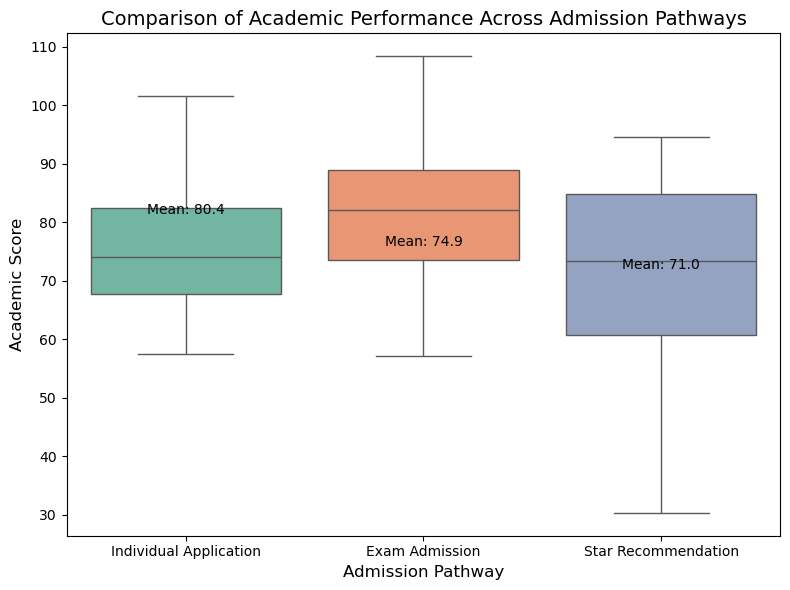

In [ ]:
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

# 讀取資料
df = pd.read_excel("Q2_students_with_scores.xlsx")

# 數據清理：只保留三種入學類型
valid_types = ["個人申請", "考試分發", "繁星推薦"]
df = df[df["入學管道"].isin(valid_types)]

# 將入學管道改成英文標籤
mapping = {
    "個人申請": "Individual Application",
    "考試分發": "Exam Admission",
    "繁星推薦": "Star Recommendation"
}
df["Admission_Type"] = df["入學管道"].map(mapping)

# 建立虛無假設與對立假設
# H0: 三組入學管道的學生平均分數相同
# H1: 至少有一組的平均分數不同

# 執行 ANOVA 單因子變異數分析
model = ols('score ~ C(入學管道)', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

# 取得統計值
f_value = anova_table["F"][0]
p_value = anova_table["PR(>F)"][0]
df_between = int(anova_table.shape[0] - 1)
df_within = int(model.df_resid)

# 統計檢定結果輸出
print("統計檢定結果：")
print(f"F({df_between},{df_within}) = {f_value:.2f}, p = {p_value:.3f}", end=" ")
if p_value < 0.05:
    print("→ 三組平均分數之間存在顯著差異。\n")

    # 事後檢定
    tukey = pairwise_tukeyhsd(endog=df["score"], groups=df["入學管道"], alpha=0.05)
    print("事後檢定結果：")
    print(tukey)

    results = tukey.summary().data[1:]  # 跳過標題列
    for row in results:
        g1, g2, meandiff, p_adj, lower, upper, reject = row
        if reject:
            print(f"• {g1} 與 {g2} 之間有顯著差異。")
        else:
            print(f"• {g1} 與 {g2} 之間沒有顯著差異。")
else:
    print("→ 三組平均分數之間沒有顯著差異。")

# 視覺化盒狀圖）
plt.figure(figsize=(8, 6))
sns.boxplot(x="Admission_Type", y="score", data=df, palette="Set2")

# 加入平均值標記
group_means = df.groupby("Admission_Type")["score"].mean()
for i, group in enumerate(group_means.index):
    plt.text(i, group_means[group] + 1, f"Mean: {group_means[group]:.1f}", 
             ha='center', color='black', fontsize=10)

plt.title("Comparison of Academic Performance Across Admission Pathways", fontsize=14)
plt.xlabel("Admission Pathway", fontsize=12)
plt.ylabel("Academic Score", fontsize=12)
plt.tight_layout()
plt.show()